# Video Games GRU4Rec: comparisons against selective GAN

This add-on evaluates **only the selective GAN checkpoint**. Baseline, full-Qwen/LLaMA and selective-Qwen/LLaMA per-user results are read from a completed original analysis folder; those models are not reevaluated or retrained.

Set **EXISTING_RUN_DIR** below to one completed output folder. This file requires the completed **Video Games GRU4Rec** results folder and verifies that its saved model and dataset match. Use the other files for the other combinations.

**Delta = comparator minus GAN.** Positive means that baseline/LLM method scores higher than GAN; negative favours GAN. All, original-history ≤7 and >7 cohorts are reported. Sensitivity excludes the union of GAN and comparator overlap flags. Baseline has no synthetic-overlap flags.

Paired t-tests and bootstrap 95% intervals cover Hit@10, NDCG@10 and MRR@10; exact McNemar supports Hit. Holm uses 45 planned comparisons per population (5 comparators ×3 cohorts ×3 metrics); supporting Hit family 15. Unavailable identities retain planned slots. Intervals are pointwise. No claim of no harm follows from nonsignificance. Different training settings limit causal attribution.

**Execution status:** code updated; actual Drive checkpoints must be evaluated in Colab. Outputs from previous analyses are preserved. Select a GPU runtime.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%pip install -q "recbole==1.2.0" kmeans-pytorch ray

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import gc
import json
import hashlib
import importlib.metadata as package_metadata
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd
import torch
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

if not hasattr(np, 'float_'):
    np.float_ = np.float64
if not hasattr(np, 'float'):
    np.float = float
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
from recbole.quick_start import load_data_and_model
from recbole.utils import get_trainer
from recbole.data.dataloader import FullSortEvalDataLoader

print({p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']})
if not torch.cuda.is_available():
    raise RuntimeError('Select a Colab GPU runtime before evaluation. Do not reinstall PyTorch blindly.')
print('GPU:', torch.cuda.get_device_name(0))
# Test an actual CUDA operation, not just device detection.
print('CUDA calculation:', (torch.ones(2, device='cuda') * 2).cpu().tolist())
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

{'torch': '2.11.0+cu130', 'recbole': '1.2.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3'}
GPU: Tesla T4
CUDA calculation: [2.0, 2.0]


### Select one existing results folder

In [ ]:
from pathlib import Path
from datetime import datetime, timezone

EXPECTED_MODEL = 'BERT4Rec'
EXPECTED_DATASET = 'VideoGames'

PROJECT = Path('/content/drive/MyDrive/Wits_Honours_Project')

EXISTING_RUN_DIR = PROJECT / (
    'results/significance/video_games_bert4rec_full_and_selective/'
    '20261015T073135_029861Z'
)

K = 10
THRESHOLD = 7
SEED = 42
BOOTSTRAP_RESAMPLES = 5000
EVAL_BATCH_SIZE = 256
METRICS = ['hit@10', 'ndcg@10', 'mrr@10']

for required in [
    'per_user/baseline.csv',
    'per_user/baseline.json',
    'preparation/checkpoint_configs.json',
]:
    path = EXISTING_RUN_DIR / required
    if not path.is_file():
        raise FileNotFoundError(
            f'Required saved result missing: {path}'
        )

RUN_DIR = (
    EXISTING_RUN_DIR / 'gan_reference'
    / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
)

for subfolder in ['preparation', 'per_user', 'analysis', 'figures']:
    (RUN_DIR / subfolder).mkdir(parents=True, exist_ok=False)

print('Reading previous results:', EXISTING_RUN_DIR)
print('New GAN comparison folder:', RUN_DIR)

Reading previous results: /content/drive/MyDrive/Wits_Honours_Project/results/significance/video_games_bert4rec_full_and_selective/20261015T073135_029861Z
New GAN comparison folder: /content/drive/MyDrive/Wits_Honours_Project/results/significance/video_games_bert4rec_full_and_selective/20261015T073135_029861Z/gan_reference/20261016T092202_763606Z


### Helpers and sequence audits

In [ ]:
def read_inter(path):
    frame = pd.read_csv(
        path, sep='\t', dtype=str, keep_default_na=False
    )
    frame.columns = [column.split(':')[0] for column in frame.columns]

    required = ['user_id', 'item_id', 'timestamp']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError(f'Invalid .inter schema or empty dataset: {path}')
    if frame[required].eq('').any().any():
        raise ValueError(f'Empty interaction fields: {path}')

    frame['timestamp'] = pd.to_numeric(
        frame['timestamp'], errors='raise'
    )
    if not np.isfinite(frame['timestamp']).all():
        raise ValueError(f'Nonfinite timestamps: {path}')

    # Match RecBole's float32 timestamp representation.
    frame['_evaluation_time'] = (
        frame['timestamp'].to_numpy(dtype=np.float32)
    )
    if not np.isfinite(frame['_evaluation_time']).all():
        raise ValueError(f'Timestamps overflow float32: {path}')

    # Preserve original file order within timestamp ties.
    frame['_file_order'] = np.arange(len(frame))

    tied = frame.duplicated(
        ['user_id', '_evaluation_time'], keep=False
    )
    print(
        f'{Path(path).name}: '
        f'{int(tied.sum())} interactions in timestamp ties; '
        f'{frame.loc[tied, "user_id"].nunique()} affected users.'
    )

    return (
        frame.sort_values(
            ['user_id', '_evaluation_time', '_file_order'],
            kind='stable'
        )
        .drop(columns=['_evaluation_time', '_file_order'])
        .reset_index(drop=True)
    )


def item_sequences(frame):
    return frame.groupby('user_id')['item_id'].agg(list).to_dict()


def is_subsequence(original, augmented):
    remaining = iter(augmented)
    return all(item in remaining for item in original)


def audit_sequences(
    original_sequences, augmented_sequences, kind, threshold=7
):
    if set(original_sequences) != set(augmented_sequences):
        raise ValueError('Audited user populations differ.')

    if kind not in {'full', 'selective'}:
        raise ValueError(f'Unexpected augmentation kind: {kind}')

    rows = []
    for user, base in original_sequences.items():
        aug = augmented_sequences[user]

        if len(base) < 3 or base[-2:] != aug[-2:]:
            raise ValueError(
                f'{user}: invalid original sequence or changed holdout targets.'
            )

        if Counter(base) - Counter(aug) or not is_subsequence(base, aug):
            raise ValueError(
                f'{user}: original item occurrences/order changed.'
            )

        should_add = (
            3 if kind == 'full' or len(base) <= threshold else 0
        )
        if len(aug) - len(base) != should_add:
            raise ValueError(
                f'{user}: augmentation count does not match {kind} policy.'
            )

        if should_add == 0 and aug != base:
            raise ValueError(
                f'{user}: supposedly unaugmented item sequence changed.'
            )

        added_training = Counter(aug[:-2]) - Counter(base[:-2])
        val_overlap = added_training[base[-2]] > 0
        test_overlap = added_training[base[-1]] > 0

        rows.append({
            'user_id': user,
            'original_length': len(base),
            'additional_interactions': should_add,
            'received_augmentation': should_add > 0,
            'validation_overlap': val_overlap,
            'test_overlap': test_overlap,
            'any_overlap': val_overlap or test_overlap,
            'validation_target': base[-2],
            'target_item': base[-1],
        })

    return pd.DataFrame(rows).set_index('user_id').sort_index()



def bootstrap_interval(differences, seed, repetitions=5000):
    # Exact ordinary user-bootstrap mean distribution, compressed by equal
    # difference values. Avoid a 5000 x 109000 resampling matrix.
    values, counts = np.unique(differences, return_counts=True)
    rng = np.random.default_rng(seed)
    means = np.empty(repetitions)
    for start in range(0, repetitions, 256):
        batch = min(256, repetitions - start)
        draws = rng.multinomial(len(differences), counts / len(differences), size=batch)
        means[start:start + batch] = draws @ values / len(differences)
    return np.quantile(means, [.025, .975])


def comparison_seed(*parts):
    return (SEED + int(hashlib.sha256('|'.join(parts).encode()).hexdigest()[:8], 16)) % (2**32)

def holm_adjust(pvalues):
    values = np.asarray(pvalues, dtype=float)
    order = np.argsort(values)
    adjusted = np.minimum(1., np.maximum.accumulate(values[order] * np.arange(len(values), 0, -1)))
    result = np.empty(len(values))
    result[order] = adjusted
    return result

def paired_summary(b, a, seed, repetitions=5000):
    b, a = np.asarray(b, dtype=float), np.asarray(a, dtype=float)
    if b.shape != a.shape or not np.isfinite(b).all() or not np.isfinite(a).all():
        raise ValueError('Invalid paired scores.')
    d = a - b
    row = {'users': len(d), 'baseline_mean': b.mean() if len(d) else np.nan,
           'augmented_mean': a.mean() if len(d) else np.nan, 'delta': d.mean() if len(d) else np.nan,
           'p_raw': np.nan, 'ci95_low': np.nan, 'ci95_high': np.nan, 'status': 'insufficient_users', 'relative_change_pct': np.nan, 'improved_pct': np.nan, 'worsened_pct': np.nan, 'unchanged_pct': np.nan}
    if len(d) < 2:
        return row
    low, high = bootstrap_interval(d, seed, repetitions)
    variance = np.std(d, ddof=1)
    row.update({'ci95_low': low, 'ci95_high': high, 'p_raw': float(stats.ttest_rel(a, b).pvalue) if variance > 0 else np.nan,
                'status': 'ok' if variance > 0 else 'zero_variance_no_t_inference',
                'relative_change_pct': 100 * d.mean() / b.mean() if b.mean() else np.nan,
                'improved_pct': 100 * np.mean(d > 0), 'worsened_pct': 100 * np.mean(d < 0),
                'unchanged_pct': 100 * np.mean(d == 0)})
    return row



### Load completed baseline and LLM scores

In [ ]:
def file_hash(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def fingerprint(tokens):
    return hashlib.sha256(json.dumps(sorted(map(str, tokens)), ensure_ascii=False).encode()).hexdigest()

provenance = json.loads((EXISTING_RUN_DIR / 'preparation/checkpoint_configs.json').read_text())
baseline_config = provenance['baseline']['config']
MODEL = baseline_config['model']
DATASET = 'VideoGames' if 'video' in baseline_config['dataset'].lower() else 'Fashion'
if MODEL not in ['SASRec', 'BERT4Rec', 'GRU4Rec'] or baseline_config['dataset'] not in ['Fashion', 'Video_Games']:
    raise ValueError('Expected an original Fashion or Video_Games sequential-model run.')
if MODEL != EXPECTED_MODEL or DATASET != EXPECTED_DATASET:
    raise ValueError(f'This notebook requires {EXPECTED_DATASET} {EXPECTED_MODEL}; selected folder contains {DATASET} {MODEL}. Set EXISTING_RUN_DIR to the matching original results folder.')
STUDY_TITLE = ('Video Games' if DATASET == 'VideoGames' else 'Fashion') + ' ' + MODEL
LABELS = {'baseline': 'Original baseline', 'full_qwen': 'Full Qwen', 'full_llama': 'Full LLaMA',
          'selective_qwen': 'Selective Qwen', 'selective_llama': 'Selective LLaMA', 'selective_gan': 'Selective GAN'}
PLANNED_COMPARATORS = ['baseline', 'full_qwen', 'full_llama', 'selective_qwen', 'selective_llama']
score_frames, evaluation_metadata, flags_by_condition, cache_manifest = {}, {}, {}, {}
UNAVAILABLE_CONDITIONS = {}
status_path = EXISTING_RUN_DIR / 'preparation/unavailable_conditions.json'
if status_path.is_file():
    UNAVAILABLE_CONDITIONS.update(json.loads(status_path.read_text()))
for label in PLANNED_COMPARATORS:
    csv_path = EXISTING_RUN_DIR / f'per_user/{label}.csv'
    meta_path = csv_path.with_suffix('.json')
    if label in UNAVAILABLE_CONDITIONS or not csv_path.is_file() or not meta_path.is_file():
        if label == 'baseline':
            raise FileNotFoundError('Completed baseline CSV and JSON are required.')
        UNAVAILABLE_CONDITIONS.setdefault(label, 'Previous per-user CSV/metadata unavailable.')
        continue
    metadata = json.loads(meta_path.read_text())
    cfg = metadata.get('config', {})
    # Preserve previously documented identity checks, including old GRU runs.
    if label == 'full_qwen' and 'llama' in str(cfg.get('dataset', '')).lower() and not metadata.get('independently_verified_source'):
        UNAVAILABLE_CONDITIONS[label] = 'Nominal Qwen checkpoint has an unverified LLaMA dataset identity.'
        continue
    if label == 'full_qwen' and provenance.get('full_qwen', {}).get('inter_sha256') == provenance.get('full_llama', {}).get('inter_sha256'):
        UNAVAILABLE_CONDITIONS[label] = 'Full Qwen and LLaMA reference identical interaction bytes.'
        continue
    frame = pd.read_csv(csv_path, dtype={'user_id': str, 'target_item': str, 'validation_target': str,
                                        'excluded_items_sha256': str}).set_index('user_id').sort_index()
    if frame.index.has_duplicates or frame.empty or not set(METRICS + ['target_item', 'validation_target', 'excluded_items_sha256']).issubset(frame.columns):
        raise ValueError(f'{label}: incomplete or duplicate cached per-user results.')
    if not np.isfinite(frame[METRICS].to_numpy()).all():
        raise ValueError(f'{label}: nonfinite cached metrics.')
    if label != 'baseline':
        flag_path = EXISTING_RUN_DIR / f'preparation/{label}_overlap_flags.csv'
        flags = pd.read_csv(flag_path, dtype={'user_id': str}).set_index('user_id').sort_index()
        if not flags.index.equals(frame.index) or flags.any_overlap.isna().any() or not flags.any_overlap.isin([True, False]).all():
            raise ValueError(f'{label}: missing or invalid saved overlap flags.')
        flags_by_condition[label] = flags
    score_frames[label], evaluation_metadata[label] = frame, metadata
    cache_manifest[label] = {'csv': str(csv_path), 'sha256': file_hash(csv_path), 'metadata': str(meta_path)}
    print('REUSED:', label, len(frame), 'users')

base = score_frames['baseline']
COMMON_USERS = list(base.index)
base_inter = Path(provenance['baseline']['inter'])
if not base_inter.is_file():
    matches = list(PROJECT.rglob(baseline_config['dataset'] + '.inter'))
    if len(matches) != 1:
        raise FileNotFoundError('Original baseline interactions moved; resolve their path explicitly.')
    base_inter = matches[0]
if file_hash(base_inter) != provenance['baseline']['inter_sha256']:
    raise ValueError('Original dataset bytes changed since the cached evaluation.')
original_frame = read_inter(base_inter)
ORIGINAL_RAW_SEQUENCES = item_sequences(original_frame)
original_sequences = {u: ORIGINAL_RAW_SEQUENCES[u] for u in COMMON_USERS}
original_lengths = pd.Series({u: len(s) for u, s in original_sequences.items()}, name='original_length').sort_index()
original_lengths.index.name = 'user_id'
flags_by_condition['baseline'] = pd.DataFrame({'original_length': original_lengths, 'any_overlap': False}, index=base.index)
COMMON_ITEMS = sorted(set(original_frame.item_id))
USE_COMMON = 'controlled' in evaluation_metadata['baseline'].get('protocol', '').lower()
if USE_COMMON:
    protocol_path = EXISTING_RUN_DIR / 'preparation/shared_evaluation_protocol.json'
    protocol = json.loads(protocol_path.read_text())
    COMMON_ITEMS = sorted(set(COMMON_ITEMS) - set(protocol['excluded_baseline_items']))
    if len(COMMON_USERS) != protocol['shared_users'] or len(COMMON_ITEMS) != protocol['shared_items']:
        raise ValueError('Cached common evaluation population cannot be reconstructed.')
if fingerprint(COMMON_ITEMS) != evaluation_metadata['baseline']['catalogue_sha256']:
    raise ValueError('Cached item catalogue differs from reconstructed original catalogue.')
print('Reusing exact evaluation task:', len(COMMON_USERS), 'users;', len(COMMON_ITEMS), 'items')
print('Unavailable methods:', UNAVAILABLE_CONDITIONS)


REUSED: baseline 109251 users
REUSED: full_qwen 109251 users
REUSED: full_llama 109251 users
REUSED: selective_qwen 109251 users
REUSED: selective_llama 109251 users
Video_Games.inter: 182289 interactions in timestamp ties; 41286 affected users.
Reusing exact evaluation task: 109251 users; 54594 items
Unavailable methods: {}


### Prepare only the GAN checkpoint

In [ ]:
GAN_RUNS = {
 ('SASRec','Fashion'): ('Oct-04-2026_17-56-49', .0112, .0054, .0037),
 ('BERT4Rec','Fashion'): ('Oct-04-2026_18-07-15', .0080, .0044, .0033),
 ('GRU4Rec','Fashion'): ('Oct-04-2026_18-14-55', .0093, .0045, .0030),
 ('SASRec','VideoGames'): ('Oct-04-2026_19-37-30', .0709, .0377, .0276),
 ('BERT4Rec','VideoGames'): ('Oct-08-2026_05-22-53', .0509, .0269, .0197),
 ('GRU4Rec','VideoGames'): ('Oct-05-2026_04-46-19', .0627, .0334, .0246),
}
stamp, hit, ndcg, mrr = GAN_RUNS[MODEL, DATASET]
checkpoint_path = PROJECT / f'saved/{MODEL.lower()}_fashion_selective_gan/{MODEL}-{stamp}.pth'
dataset_name = ('Video_Games' if DATASET == 'VideoGames' else 'Fashion') + '_selective_gan_augmented'
gan_inter = PROJECT / 'datasets' / dataset_name / (dataset_name + '.inter')
for path in [checkpoint_path, gan_inter]:
    if not path.is_file():
        raise FileNotFoundError(path)
expected_hash = ('7d67c69d1ec35e12a56b9b19a26a4eed6d882d013e32a4da2f30be4d09de9259' if DATASET == 'VideoGames'
                 else 'd3ebd52fde17fb3c85e8b2bbd5bfbddd0a7c6a143c0cf24daf9d4bb7e2cc7eaa')
if file_hash(gan_inter) != expected_hash:
    raise ValueError('GAN dataset differs from the export recorded in gan.ipynb; verify its source.')
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
config = checkpoint['config']
settings = config.final_config_dict if hasattr(config, 'final_config_dict') else config
if settings['model'] != MODEL or settings['dataset'] != dataset_name or K not in settings['topk']:
    raise ValueError('GAN saved model/dataset/top-K identity differs from the selected study.')
saved_gan_config = {k: settings.get(k) for k in baseline_config}
settings['data_path'] = str(gan_inter.parent)
settings['eval_batch_size'] = EVAL_BATCH_SIZE
settings['device'] = torch.device('cuda:0')
settings['use_gpu'] = True
settings['gpu_id'] = '0'
temporary = Path('/content/gan_reference_evaluation') / f'{MODEL}_{DATASET}_{file_hash(checkpoint_path)[:12]}.pth'
temporary.parent.mkdir(exist_ok=True, parents=True)
torch.save(checkpoint, temporary)
provenance['selective_gan'] = {'checkpoint': str(checkpoint_path), 'checkpoint_sha256': file_hash(checkpoint_path),
    'inter': str(gan_inter), 'inter_sha256': file_hash(gan_inter), 'config': saved_gan_config,
    'saved_epoch': checkpoint.get('epoch'), 'evaluation_checkpoint_path': str(temporary)}
del checkpoint
RUNS = {'selective_gan': {'kind': 'selective', 'checkpoint': str(checkpoint_path),
                        'recorded': {'hit@10': hit, 'ndcg@10': ndcg, 'mrr@10': mrr}}}
evaluation_checkpoint_paths = {'selective_gan': temporary}
gan_raw_frame = read_inter(gan_inter)
gan_sequences = item_sequences(gan_raw_frame)
if not set(COMMON_USERS).issubset(gan_sequences) or not set(COMMON_ITEMS).issubset(set(gan_raw_frame.item_id)):
    raise ValueError('GAN lacks users/items from the cached task; cached comparisons cannot be reused unchanged.')
raw_sequences = {'selective_gan': gan_sequences}
flags_by_condition['selective_gan'] = audit_sequences(original_sequences,
    {u: gan_sequences[u] for u in COMMON_USERS}, 'selective', THRESHOLD)
flags_by_condition['selective_gan'].reset_index().to_csv(RUN_DIR / 'preparation/selective_gan_overlap_flags.csv', index=False)
native_overview_rows = []
print('Prepared GAN only:', checkpoint_path)


Video_Games_selective_gan_augmented.inter: 0 interactions in timestamp ties; 0 affected users.
Prepared GAN only: /content/drive/MyDrive/Wits_Honours_Project/saved/bert4rec_fashion_selective_gan/BERT4Rec-Oct-08-2026_05-22-53.pth


### GAN exporter for the existing native or common-catalogue protocol

In [ ]:
def export_native_gan(label):
    checkpoint_path = PROJECT / RUNS[label]['checkpoint']
    config, model, dataset, train, valid, test = load_data_and_model(str(evaluation_checkpoint_paths[label]))
    if not isinstance(valid, FullSortEvalDataLoader) or not isinstance(test, FullSortEvalDataLoader):
        raise ValueError('Full-sort validation and test are required.')
    if not config['single_spec']:
        raise ValueError('Single-process evaluation is required.')
    trainer = get_trainer(config['MODEL_TYPE'], config['model'])(config, model)
    trainer.eval_collector.data_collect(train)
    native_collect = trainer.eval_collector.eval_batch_collect
    captured = []
    uid, iid = config['USER_ID_FIELD'], config['ITEM_ID_FIELD']

    def capture(scores, interaction, positive_u, positive_i):
        native_collect(scores, interaction, positive_u, positive_i)
        rows = positive_u.detach().cpu().numpy()
        items = positive_i.detach().cpu().numpy()
        if not np.array_equal(np.sort(rows), np.arange(scores.shape[0])):
            raise ValueError('Exactly one held-out item per user is required.')
        if torch.isnan(scores).any() or torch.isposinf(scores).any():
            raise ValueError('Invalid model scores.')
        targets = np.empty(scores.shape[0], dtype=int)
        targets[rows] = items
        users = dataset.id2token(uid, interaction[uid].detach().cpu().numpy())
        target_tokens = dataset.id2token(iid, targets)
        top = torch.topk(scores, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        target_scores = scores[torch.arange(len(targets), device=scores.device), torch.as_tensor(targets, device=scores.device)]
        if not torch.isfinite(target_scores).all():
            raise ValueError('Held-out target is masked/nonfinite.')
        exclusions = torch.isneginf(scores).cpu().numpy()
        for row, user in enumerate(users):
            found = np.flatnonzero(top[row] == targets[row])
            rank = int(found[0] + 1) if len(found) else 0
            captured.append({'user_id': str(user), 'target_item': str(target_tokens[row]), 'top10_rank': rank,
                             'hit@10': int(rank > 0), 'ndcg@10': 1 / np.log2(rank + 1) if rank else 0.,
                             'mrr@10': 1 / rank if rank else 0.,
                             'excluded_items_sha256': fingerprint(dataset.id2token(iid, np.flatnonzero(exclusions[row])))})

    trainer.eval_collector.eval_batch_collect = capture
    try:
        trainer.evaluate(valid, load_best_model=False, show_progress=True)
        val = pd.DataFrame(captured)
        captured.clear()
        native_results = trainer.evaluate(test, load_best_model=False, show_progress=True)
        frame = pd.DataFrame(captured)
    finally:
        trainer.eval_collector.eval_batch_collect = native_collect
    if val.empty or frame.empty or val.user_id.duplicated().any() or frame.user_id.duplicated().any():
        raise ValueError('Empty/repeated evaluation users.')
    frame['validation_target'] = frame.user_id.map(val.set_index('user_id').target_item)
    frame = frame.set_index('user_id').sort_index()
    if set(frame.index) != set(original_sequences) or frame.validation_target.isna().any():
        raise ValueError(f'{label}: filtered evaluation user population differs from original.')
    expected = pd.DataFrame.from_dict({u: {'validation_target': s[-2], 'target_item': s[-1]} for u, s in original_sequences.items()}, orient='index').sort_index()
    for field in ['validation_target', 'target_item']:
        if not np.array_equal(frame[field].to_numpy(), expected[field].to_numpy()):
            raise ValueError(f'{label}: native {field} does not match audited original split.')
    tolerance = 10 ** (-config['metric_decimal_place']) + 1e-9
    checks = []
    for metric in METRICS:
        exported, native = float(frame[metric].mean()), float(native_results[metric])
        recorded = RUNS[label]['recorded'][metric]
        if abs(exported - native) > tolerance or abs(exported - recorded) > tolerance:
            raise ValueError(f'{label}: {metric} failed reproduction: export={exported}, native={native}, recorded={recorded}')
        checks.append({'condition': label, 'metric': metric, 'exported': exported, 'native': native, 'recorded': recorded})
    if abs(float(native_results['recall@10']) - float(frame['hit@10'].mean())) > tolerance:
        raise ValueError('Recall and Hit disagree under one-positive evaluation.')
    output_path = RUN_DIR / f'per_user/{label}.csv'
    frame.reset_index().to_csv(output_path, index=False)
    metadata = {**provenance[label], 'catalogue_sha256': fingerprint(dataset.field2id_token[iid][1:]),
                'eval_args': config['eval_args'], 'topk': config['topk'], 'k': K,
                'native_test_results': {k: float(v) for k, v in native_results.items()}, 'users': len(frame)}
    output_path.with_suffix('.json').write_text(json.dumps(metadata, indent=2, default=str))
    del trainer, model, dataset, train, valid, test
    gc.collect()
    torch.cuda.empty_cache()
    return frame, metadata, checks

def export_common_gan(label):
    checkpoint_path = PROJECT / RUNS[label]['checkpoint']
    config, model, dataset, train, valid, test = load_data_and_model(str(evaluation_checkpoint_paths[label]))
    if not isinstance(valid, FullSortEvalDataLoader) or not isinstance(test, FullSortEvalDataLoader) or not config['single_spec']:
        raise ValueError('Require single-process full-sort validation/test evaluation.')
    trainer = get_trainer(config['MODEL_TYPE'], config['model'])(config, model)
    trainer.eval_collector.data_collect(train)
    native_collect = trainer.eval_collector.eval_batch_collect
    captured_native, captured_common = [], []
    uid, iid = config['USER_ID_FIELD'], config['ITEM_ID_FIELD']
    model_tokens = set(map(str, dataset.field2id_token[iid][1:]))
    if not set(COMMON_ITEMS).issubset(model_tokens):
        raise ValueError(f'{label}: filtered model catalogue lacks a common item.')
    common_iids = dataset.token2id(iid, np.asarray(COMMON_ITEMS))
    common_tensor = torch.as_tensor(common_iids, device=config['device'], dtype=torch.long)
    common_id_set = set(map(int, common_iids))
    excluded_ids = np.array([i for i in range(dataset.item_num) if i not in common_id_set], dtype=int)
    excluded_tensor = torch.as_tensor(excluded_ids, device=config['device'], dtype=torch.long)
    shared_user_set = set(COMMON_USERS)

    def capture(scores, interaction, positive_u, positive_i):
        # Native collector sees untouched native scores for historical reproduction.
        native_collect(scores, interaction, positive_u, positive_i)
        rows, items = positive_u.cpu().numpy(), positive_i.cpu().numpy()
        if not np.array_equal(np.sort(rows), np.arange(scores.shape[0])):
            raise ValueError('Require one held-out target per evaluation row.')
        if torch.isnan(scores).any() or torch.isposinf(scores).any():
            raise ValueError('Invalid model scores.')
        targets = np.empty(scores.shape[0], dtype=int)
        targets[rows] = items
        users = dataset.id2token(uid, interaction[uid].cpu().numpy())
        target_tokens = dataset.id2token(iid, targets)
        native_top = torch.topk(scores, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        controlled = scores.clone()
        controlled[:, excluded_tensor] = -np.inf
        common_top = torch.topk(controlled, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        excluded_common = torch.isneginf(controlled[:, common_tensor]).cpu().numpy()
        target_tensor = torch.as_tensor(targets, device=scores.device)
        row_tensor = torch.arange(len(targets), device=scores.device)
        if not torch.isfinite(scores[row_tensor, target_tensor]).all():
            raise ValueError('Native held-out target masked/nonfinite.')
        shared_mask = torch.as_tensor([str(u) in shared_user_set for u in users], device=scores.device)
        if not torch.isfinite(controlled[row_tensor[shared_mask], target_tensor[shared_mask]]).all():
            raise ValueError('Controlled shared-user target masked/nonfinite.')
        for row, user_token in enumerate(users):
            user, target = str(user_token), str(target_tokens[row])
            def record(top):
                found = np.flatnonzero(top[row] == targets[row])
                rank = int(found[0] + 1) if len(found) else 0
                return {'user_id': user, 'target_item': target, 'top10_rank': rank,
                        'hit@10': int(rank > 0), 'ndcg@10': 1 / np.log2(rank + 1) if rank else 0.,
                        'mrr@10': 1 / rank if rank else 0.}
            captured_native.append(record(native_top))
            if user in shared_user_set:
                entry = record(common_top)
                entry['excluded_items_sha256'] = fingerprint(np.asarray(COMMON_ITEMS)[excluded_common[row]])
                captured_common.append(entry)

    trainer.eval_collector.eval_batch_collect = capture
    try:
        trainer.evaluate(valid, load_best_model=False, show_progress=True)
        val_native, val_common = pd.DataFrame(captured_native), pd.DataFrame(captured_common)
        captured_native.clear(); captured_common.clear()
        native_results = trainer.evaluate(test, load_best_model=False, show_progress=True)
        native_frame, frame = pd.DataFrame(captured_native), pd.DataFrame(captured_common)
    finally:
        trainer.eval_collector.eval_batch_collect = native_collect
    for test_frame, validation_frame in [(native_frame, val_native), (frame, val_common)]:
        if test_frame.empty or validation_frame.empty or test_frame.user_id.duplicated().any() or validation_frame.user_id.duplicated().any():
            raise ValueError('Empty or repeated evaluation users.')
        test_frame['validation_target'] = test_frame.user_id.map(validation_frame.set_index('user_id').target_item)
        if test_frame.validation_target.isna().any():
            raise ValueError('Missing validation targets.')
    native_frame = native_frame.set_index('user_id').sort_index()
    frame = frame.set_index('user_id').sort_index()
    if set(native_frame.index) != set(raw_sequences[label]) or set(frame.index) != set(COMMON_USERS):
        raise ValueError(f'{label}: filtered user coverage differs from audited input.')
    for u, row in native_frame.iterrows():
        if [row.validation_target, row.target_item] != ORIGINAL_RAW_SEQUENCES[u][-2:]:
            raise ValueError(f'{label}: native held-out split differs for {u}.')
    checks = []
    tolerance = 10 ** (-config['metric_decimal_place']) + 1e-9
    for metric in METRICS:
        exported, native, recorded = float(native_frame[metric].mean()), float(native_results[metric]), RUNS[label]['recorded'][metric]
        if abs(exported - native) > tolerance or abs(exported - recorded) > tolerance:
            raise ValueError(f'{label}: historical {metric} reproduction failed: {exported}, {native}, {recorded}')
        checks.append({'condition': label, 'metric': metric, 'native_exported': exported, 'native_recbole': native,
                       'recorded': recorded, 'controlled_common_mean': float(frame[metric].mean())})
    if abs(float(native_results['recall@10']) - float(native_frame['hit@10'].mean())) > tolerance:
        raise ValueError('Native Recall/Hit mismatch.')
    native_lengths = pd.Series({u: len(ORIGINAL_RAW_SEQUENCES[u]) for u in native_frame.index}, index=native_frame.index)
    for group in ['all', 'sparse', 'longer_history']:
        selected = native_frame if group == 'all' else native_frame.loc[native_lengths <= THRESHOLD if group == 'sparse' else native_lengths > THRESHOLD]
        native_overview_rows.append({'condition': label, 'group': group, 'protocol': 'historical native ranking',
                                     'users': len(selected), 'items': len(model_tokens),
                                     **{m: float(selected[m].mean()) for m in METRICS}})
    native_frame.reset_index().to_csv(RUN_DIR / f'per_user/{label}_native.csv', index=False)
    output_path = RUN_DIR / f'per_user/{label}.csv'
    frame.reset_index().to_csv(output_path, index=False)
    metadata = {**provenance[label], 'catalogue_sha256': fingerprint(COMMON_ITEMS),
                'eval_args': config['eval_args'], 'topk': config['topk'], 'k': K,
                'protocol': 'controlled shared users and common candidate catalogue',
                'native_test_results': {k: float(v) for k, v in native_results.items()},
                'controlled_test_means': {m: float(frame[m].mean()) for m in METRICS},
                'native_users': len(native_frame), 'users': len(frame)}
    output_path.with_suffix('.json').write_text(json.dumps(metadata, indent=2, default=str))
    del trainer, model, dataset, train, valid, test
    gc.collect(); torch.cuda.empty_cache()
    return frame, metadata, checks


### Evaluate GAN once and verify pairing

In [ ]:
# Evaluate GAN once; do not evaluate the cached baseline or LLM checkpoints.
export_gan = export_common_gan if USE_COMMON else export_native_gan
frame, metadata, checks = export_gan('selective_gan')
score_frames['selective_gan'] = frame
evaluation_metadata['selective_gan'] = metadata
pd.DataFrame(checks).to_csv(RUN_DIR / 'analysis/gan_reproduction_checks.csv', index=False)
display(pd.DataFrame(checks))
for label, scores in score_frames.items():
    if not scores.index.equals(frame.index):
        raise ValueError(f'{label}: cached evaluation users differ from GAN.')
    for field in ['target_item', 'validation_target', 'excluded_items_sha256']:
        if not scores[field].equals(frame[field]):
            raise ValueError(f'{label}: different {field}; cannot make a paired comparison.')
    for field in ['catalogue_sha256', 'eval_args', 'topk', 'k']:
        if evaluation_metadata[label][field] != metadata[field]:
            raise ValueError(f'{label}: different evaluation setting {field}.')
print('GAN scores reproduced and evaluation task matches cached results.')


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset

,condition,metric,native_exported,native_recbole,recorded,controlled_common_mean
0,selective_gan,hit@10,0.050861,0.0509,0.0509,0.050865
1,selective_gan,ndcg@10,0.026875,0.0269,0.0269,0.026877
2,selective_gan,mrr@10,0.019654,0.0197,0.0197,0.019655


GAN scores reproduced and evaluation task matches cached results.


### Tests with GAN as reference

In [ ]:
GROUPS = ['all', 'sparse', 'longer_history']
POPULATIONS = ['all_users_exploratory', 'overlap_excluded_sensitivity']
COMPARATORS = [label for label in PLANNED_COMPARATORS if label in score_frames]
gan_scores = score_frames['selective_gan']
rows = []
for label in COMPARATORS:
    other = score_frames[label]
    union_overlap = flags_by_condition[label].any_overlap | flags_by_condition['selective_gan'].any_overlap
    for population in POPULATIONS:
        included = np.ones(len(other), dtype=bool) if population == 'all_users_exploratory' else ~union_overlap.to_numpy()
        for group in GROUPS:
            group_mask = (np.ones(len(other), dtype=bool) if group == 'all' else
                          (original_lengths.to_numpy() <= THRESHOLD if group == 'sparse' else original_lengths.to_numpy() > THRESHOLD))
            mask = included & group_mask
            for metric in METRICS:
                g, a = gan_scores[metric].to_numpy()[mask], other[metric].to_numpy()[mask]
                row = paired_summary(g, a, comparison_seed('GAN_reference', label, population, group, metric), BOOTSTRAP_RESAMPLES)
                row['gan_mean'] = row.pop('baseline_mean')
                row['comparator_mean'] = row.pop('augmented_mean')
                row.update(comparator=label, population=population, group=group, metric=metric)
                if metric == 'hit@10':
                    gains, losses = int((a > g).sum()), int((a < g).sum())
                    row.update(gained_vs_gan=gains, lost_vs_gan=losses,
                               mcnemar_p_raw=float(stats.binomtest(gains, gains + losses).pvalue) if gains + losses else 1.)
                rows.append(row)
results = pd.DataFrame(rows)
results['p_holm'] = np.nan
results['mcnemar_p_holm'] = np.nan
for population in POPULATIONS:
    ix = results.index[results.population.eq(population)]
    raw = results.loc[ix, 'p_raw']
    adjusted = holm_adjust(np.r_[raw.fillna(1.).to_numpy(), np.ones(45 - len(raw))])[:len(raw)]
    results.loc[ix, 'p_holm'] = np.where(raw.notna(), adjusted, np.nan)
    hi = results.index[results.population.eq(population) & results.metric.eq('hit@10')]
    hp = results.loc[hi, 'mcnemar_p_raw']
    results.loc[hi, 'mcnemar_p_holm'] = holm_adjust(np.r_[hp.to_numpy(), np.ones(15 - len(hp))])[:len(hp)]
results.to_csv(RUN_DIR / 'analysis/comparisons_vs_gan.csv', index=False)
for metric in METRICS:
    print(metric, '— delta = comparator minus GAN; positive favours comparator')
    display(results.loc[results.metric.eq(metric), ['comparator', 'population', 'group', 'users', 'gan_mean',
            'comparator_mean', 'delta', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']].round(6))
manifest = {'source_results': str(EXISTING_RUN_DIR), 'cached_inputs': cache_manifest,
            'reference': 'selective_gan', 'delta': 'comparator minus GAN', 'gan': provenance['selective_gan'],
            'comparison_family_per_population':45, 'supporting_hit_mcnemar_family_per_population':15,
            'unavailable_conditions':UNAVAILABLE_CONDITIONS, 'seed':SEED, 'bootstrap_resamples':BOOTSTRAP_RESAMPLES,
            'limitations':['Fixed-checkpoint inference', 'Training settings differ', 'Overlap exclusions do not undo training influence',
                          'Pointwise intervals; adjusted p-values govern multiple comparisons', 'Correction is per notebook, not thesis-wide']}
(RUN_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))


hit@10 — delta = comparator minus GAN; positive favours comparator


,comparator,population,group,users,gan_mean,comparator_mean,delta,ci95_low,ci95_high,p_raw,p_holm
0,baseline,all_users_exploratory,all,109251,0.050865,0.030517,-0.020348,-0.021629,-0.019020,0.000000,0.000000
3,baseline,all_users_exploratory,sparse,69069,0.046041,0.032591,-0.013450,-0.015057,-0.011901,0.000000,0.000000
6,baseline,all_users_exploratory,longer_history,40182,0.059156,0.026952,-0.032203,-0.034468,-0.029963,0.000000,0.000000
9,baseline,overlap_excluded_sensitivity,all,109049,0.050656,0.030418,-0.020239,-0.021550,-0.018872,0.000000,0.000000
12,baseline,overlap_excluded_sensitivity,sparse,68867,0.045697,0.032439,-0.013257,-0.014797,-0.011675,0.000000,0.000000
15,baseline,overlap_excluded_sensitivity,longer_history,40182,0.059156,0.026952,-0.032203,-0.034543,-0.029914,0.000000,0.000000
18,full_qwen,all_users_exploratory,all,109251,0.050865,0.019881,-0.030984,-0.032302,-0.029592,0.000000,0.000000
21,full_qwen,all_users_exploratory,sparse,69069,0.046041,0.021457,-0.024584,-0.026192,-0.022905,0.000000,0.000000
24,full_qwen,all_users_exploratory,longer_history,40182,0.059156,0.017172,-0.041984,-0.044398,-0.039694,0.000000,0.000000
27,full_qwen,overlap_excluded_sensitivity,all,108260,0.050369,0.019869,-0.030501,-0.031831,-0.029161,0.000000,0.000000


ndcg@10 — delta = comparator minus GAN; positive favours comparator


,comparator,population,group,users,gan_mean,comparator_mean,delta,ci95_low,ci95_high,p_raw,p_holm
1,baseline,all_users_exploratory,all,109251,0.026877,0.015766,-0.011110,-0.011842,-0.010372,0.000000,0.000000
4,baseline,all_users_exploratory,sparse,69069,0.024570,0.017121,-0.007449,-0.008367,-0.006510,0.000000,0.000000
7,baseline,all_users_exploratory,longer_history,40182,0.030840,0.013437,-0.017404,-0.018712,-0.016080,0.000000,0.000000
10,baseline,overlap_excluded_sensitivity,all,109049,0.026754,0.015705,-0.011049,-0.011807,-0.010297,0.000000,0.000000
13,baseline,overlap_excluded_sensitivity,sparse,68867,0.024369,0.017029,-0.007340,-0.008301,-0.006425,0.000000,0.000000
16,baseline,overlap_excluded_sensitivity,longer_history,40182,0.030840,0.013437,-0.017404,-0.018709,-0.016061,0.000000,0.000000
19,full_qwen,all_users_exploratory,all,109251,0.026877,0.010428,-0.016448,-0.017247,-0.015653,0.000000,0.000000
22,full_qwen,all_users_exploratory,sparse,69069,0.024570,0.011338,-0.013232,-0.014154,-0.012296,0.000000,0.000000
25,full_qwen,all_users_exploratory,longer_history,40182,0.030840,0.008864,-0.021976,-0.023358,-0.020614,0.000000,0.000000
28,full_qwen,overlap_excluded_sensitivity,all,108260,0.026582,0.010440,-0.016142,-0.016921,-0.015399,0.000000,0.000000


mrr@10 — delta = comparator minus GAN; positive favours comparator


,comparator,population,group,users,gan_mean,comparator_mean,delta,ci95_low,ci95_high,p_raw,p_holm
2,baseline,all_users_exploratory,all,109251,0.019655,0.011327,-0.008328,-0.009018,-0.007669,0.000000,0.000000
5,baseline,all_users_exploratory,sparse,69069,0.018103,0.012460,-0.005643,-0.006482,-0.004780,0.000000,0.000000
8,baseline,all_users_exploratory,longer_history,40182,0.022322,0.009380,-0.012942,-0.014065,-0.011795,0.000000,0.000000
11,baseline,overlap_excluded_sensitivity,all,109049,0.019559,0.011279,-0.008280,-0.008968,-0.007602,0.000000,0.000000
14,baseline,overlap_excluded_sensitivity,sparse,68867,0.017946,0.012387,-0.005559,-0.006351,-0.004774,0.000000,0.000000
17,baseline,overlap_excluded_sensitivity,longer_history,40182,0.022322,0.009380,-0.012942,-0.014104,-0.011810,0.000000,0.000000
20,full_qwen,all_users_exploratory,all,109251,0.019655,0.007617,-0.012038,-0.012707,-0.011361,0.000000,0.000000
23,full_qwen,all_users_exploratory,sparse,69069,0.018103,0.008333,-0.009770,-0.010582,-0.008950,0.000000,0.000000
26,full_qwen,all_users_exploratory,longer_history,40182,0.022322,0.006385,-0.015937,-0.017150,-0.014767,0.000000,0.000000
29,full_qwen,overlap_excluded_sensitivity,all,108260,0.019423,0.007636,-0.011787,-0.012469,-0.011085,0.000000,0.000000


4405

### Hit, NDCG and MRR plots versus GAN

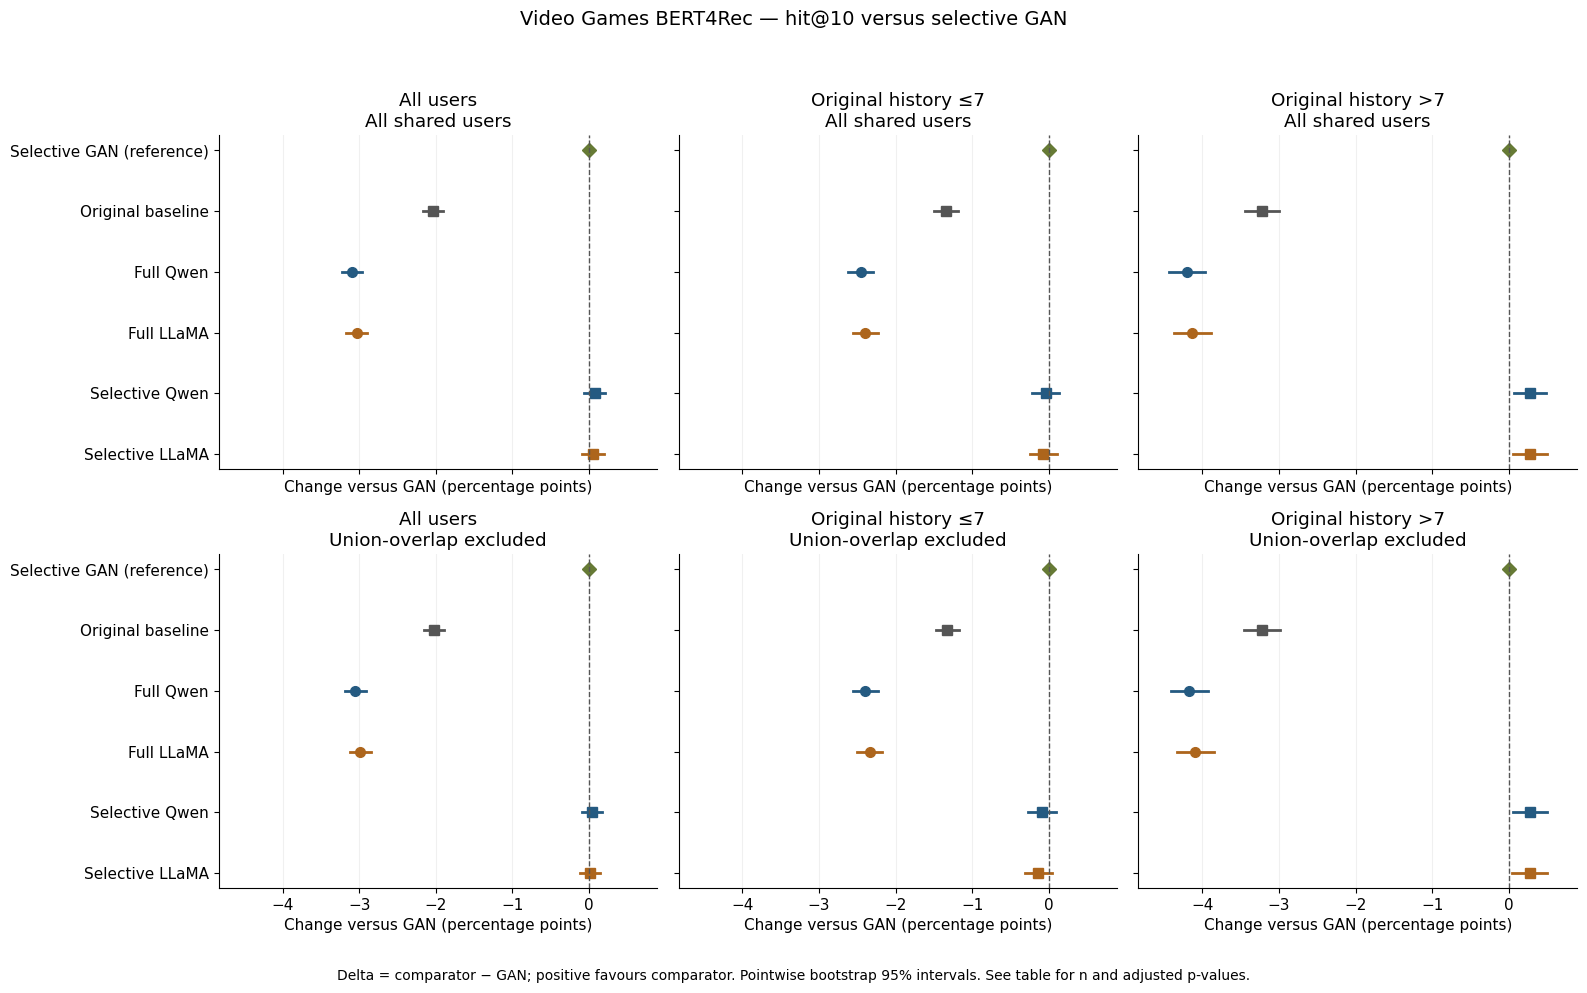

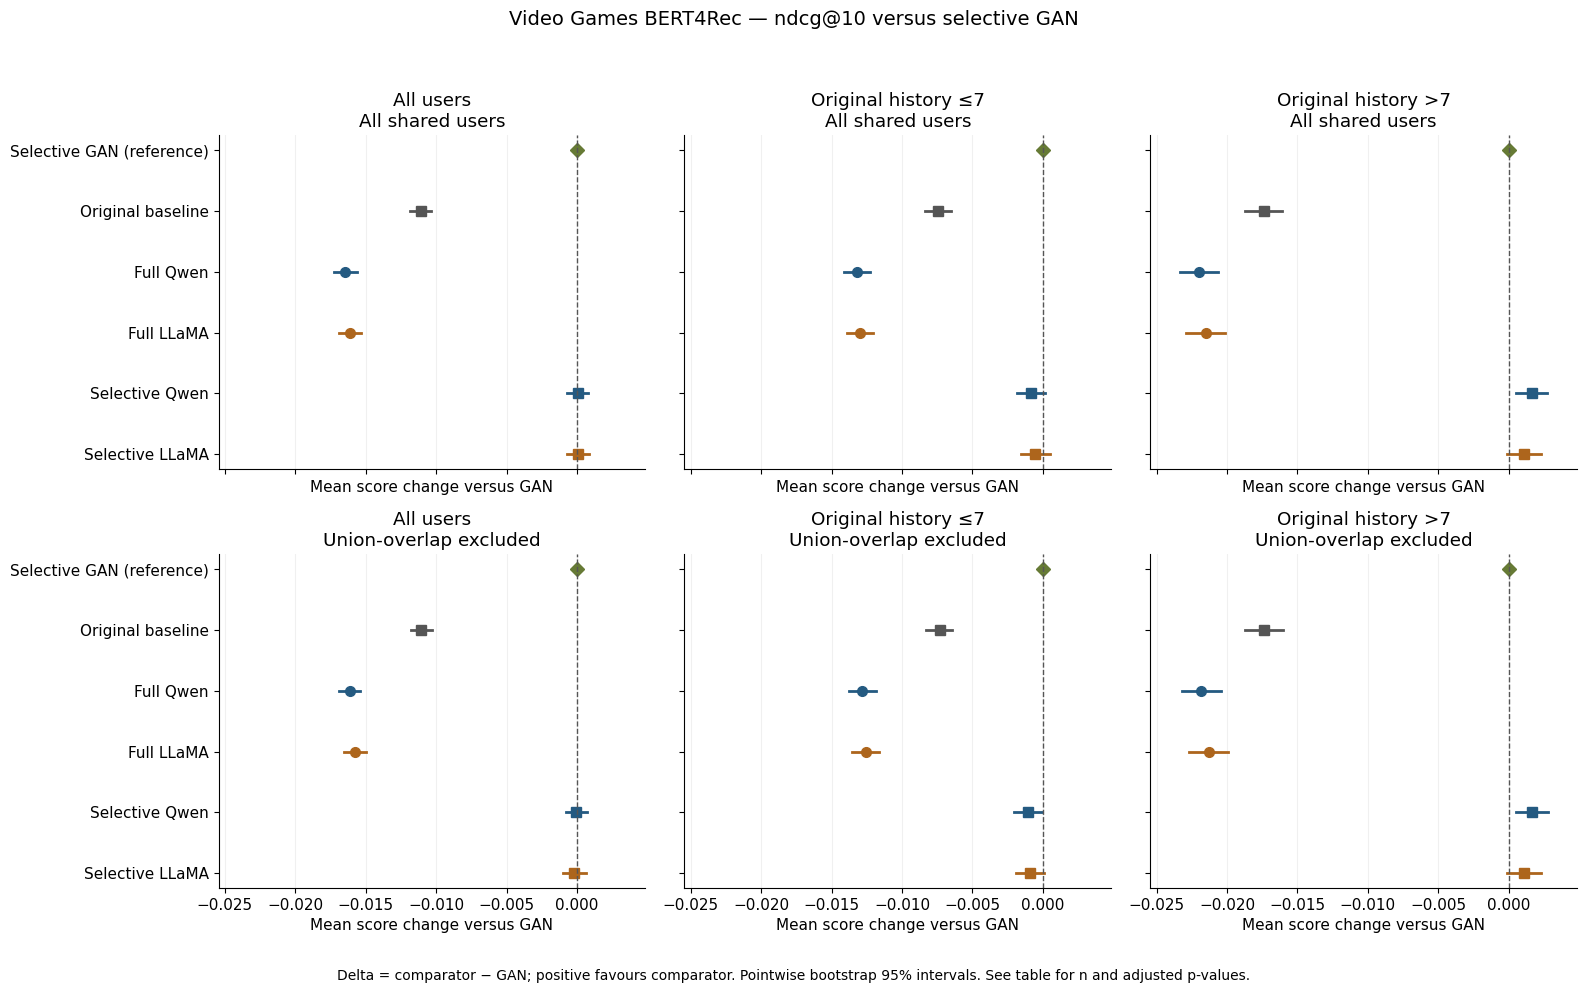

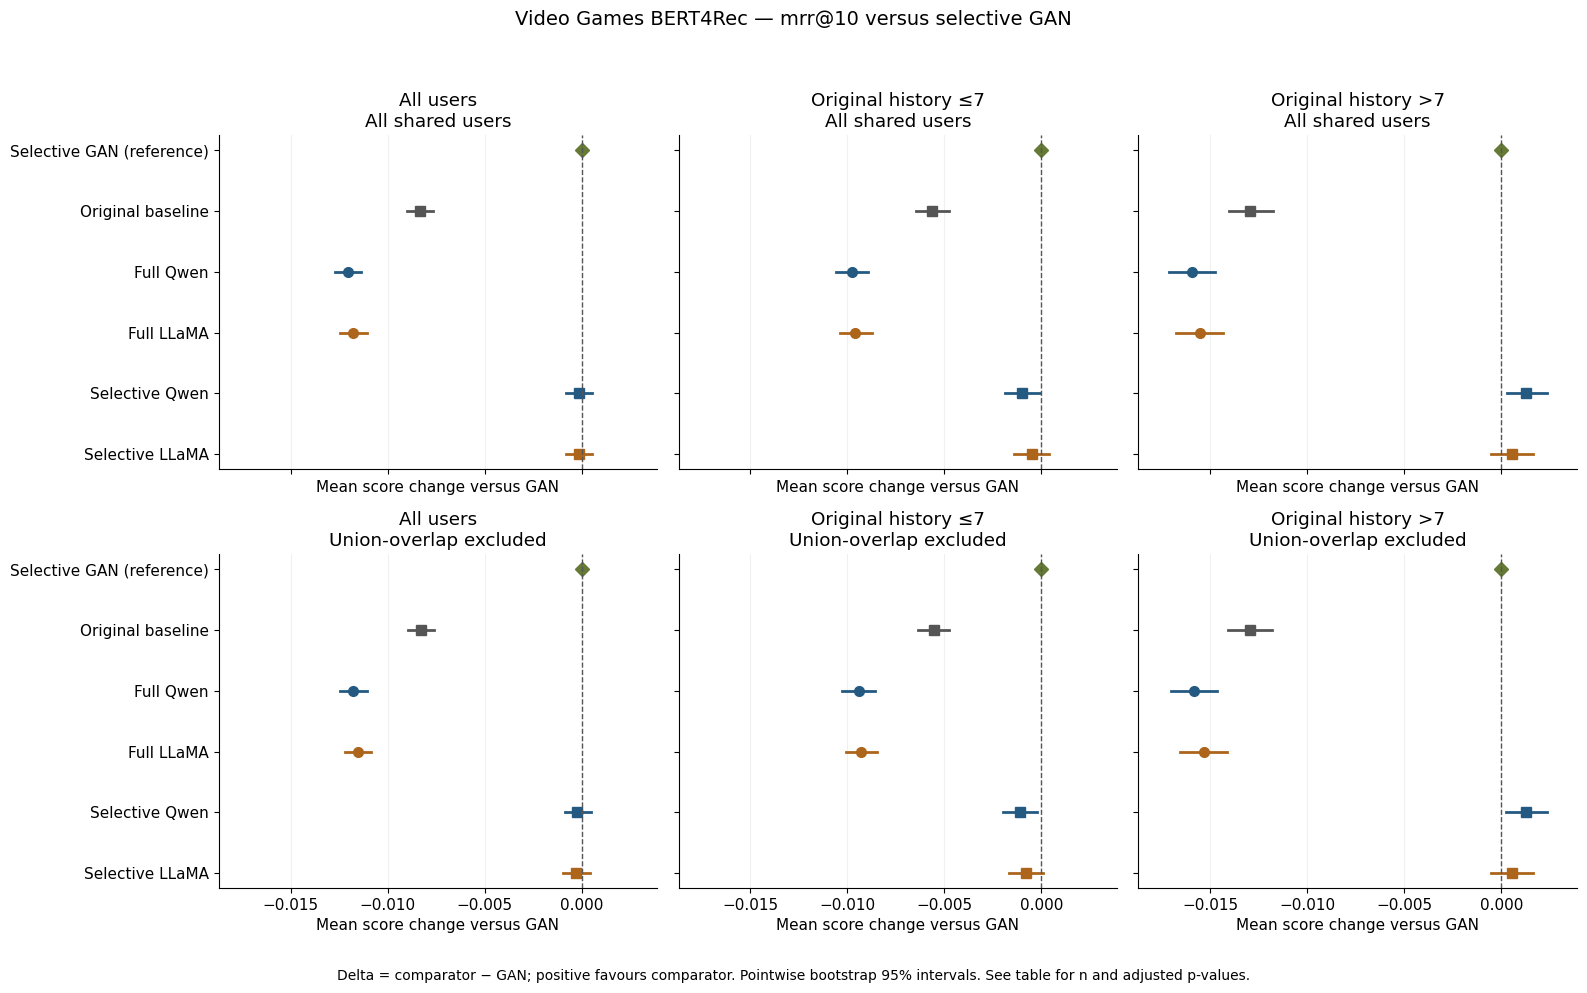

Saved GAN-reference analysis: /content/drive/MyDrive/Wits_Honours_Project/results/significance/video_games_bert4rec_full_and_selective/20261015T073135_029861Z/gan_reference/20261016T092202_763606Z


In [ ]:
COLORS = {'baseline':'#555555', 'full_qwen':'#245A81', 'selective_qwen':'#245A81',
          'full_llama':'#AD651C', 'selective_llama':'#AD651C'}
GROUP_TITLES = {'all':'All users', 'sparse':'Original history ≤7', 'longer_history':'Original history >7'}
for metric in METRICS:
    scale = 100. if metric == 'hit@10' else 1.
    selected = results.loc[results.metric.eq(metric)]
    bounds = selected[['ci95_low','ci95_high','delta']].to_numpy(dtype=float) * scale
    finite = bounds[np.isfinite(bounds)]
    low, high = (min(0., finite.min()), max(0., finite.max())) if len(finite) else (-.001,.001)
    span = max(high-low,.1 if metric=='hit@10' else .001)
    fig, axes = plt.subplots(2,3,figsize=(16,10),sharex=True,sharey=True)
    for r, population in enumerate(POPULATIONS):
        for axis, group in zip(axes[r],GROUPS):
            data = selected.loc[selected.population.eq(population) & selected.group.eq(group)].set_index('comparator')
            axis.plot(0,0,marker='D',color='#667A35',markersize=7)
            for y,label in enumerate(COMPARATORS,start=1):
                row=data.loc[label]
                axis.plot([row.ci95_low*scale,row.ci95_high*scale],[y,y],color=COLORS[label],linewidth=2)
                axis.plot(row.delta*scale,y,marker='o' if label.startswith('full') else 's',color=COLORS[label],markersize=7)
            axis.axvline(0,color='#555555',linestyle='--',linewidth=1)
            axis.set_xlim(low-.08*span,high+.08*span)
            axis.set_yticks(range(len(COMPARATORS)+1),['Selective GAN (reference)']+[LABELS[l] for l in COMPARATORS])
            axis.set_title(GROUP_TITLES[group]+'\n'+('All shared users' if r==0 else 'Union-overlap excluded'))
            axis.set_xlabel('Change versus GAN (percentage points)' if metric=='hit@10' else 'Mean score change versus GAN')
            axis.grid(axis='x',alpha=.18)
    axes[0,0].invert_yaxis()
    fig.suptitle(STUDY_TITLE+' — '+metric+' versus selective GAN',fontsize=14)
    fig.text(.5,.01,'Delta = comparator − GAN; positive favours comparator. Pointwise bootstrap 95% intervals. See table for n and adjusted p-values.',ha='center',fontsize=10)
    fig.tight_layout(rect=[0,.04,1,.95])
    fig.savefig(RUN_DIR/'figures'/f'{metric.replace("@","_")}_vs_gan.png',dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)
print('Saved GAN-reference analysis:',RUN_DIR)
